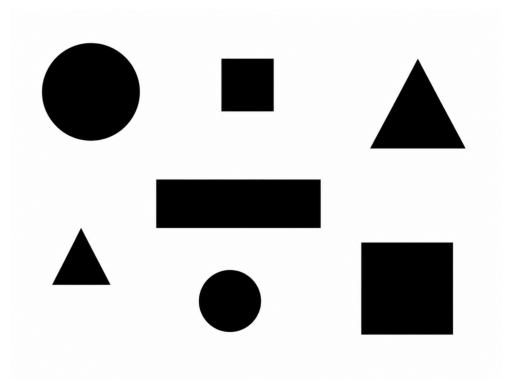

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

figury = cv2.imread("obraz_figury.jpg")
figury_rgb = cv2.cvtColor(figury, cv2.COLOR_BGR2RGB)
figury_szare = cv2.cvtColor(figury, cv2.COLOR_BGR2GRAY)
plt.imshow(figury_rgb)
plt.axis("off")
plt.show()

Liczba znalezionych konturow: 7


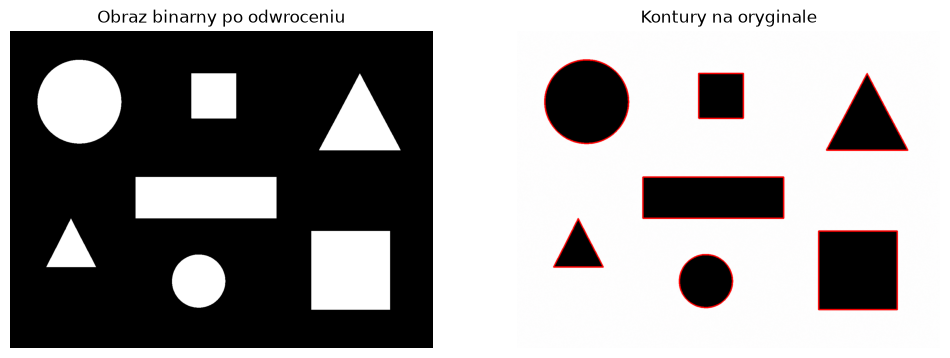

In [2]:
prog, binarny = cv2.threshold(figury_szare, 127, 255, cv2.THRESH_BINARY_INV)
kontury, hierarchia = cv2.findContours(
    binarny, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
print("Liczba znalezionych konturow:", len(kontury))
z_konturami = figury_rgb.copy()
cv2.drawContours(z_konturami, kontury, -1, (255, 0, 0), 3)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(binarny, cmap="gray")
plt.title("Obraz binarny po odwroceniu")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(z_konturami)
plt.title("Kontury na oryginale")
plt.axis("off")
plt.show()

Kontur 0: pole = 25878, obwod = 602, prostokat = 183 x 182
Kontur 1: pole = 72361, obwod = 1076, prostokat = 270 x 270
Kontur 2: pole = 14017, obwod = 572, prostokat = 171 x 167
Kontur 3: pole = 67962, obwod = 1246, prostokat = 483 x 142
Kontur 4: pole = 36619, obwod = 919, prostokat = 279 x 264
Kontur 5: pole = 23561, obwod = 613, prostokat = 154 x 155
Kontur 6: pole = 64306, obwod = 949, prostokat = 288 x 287


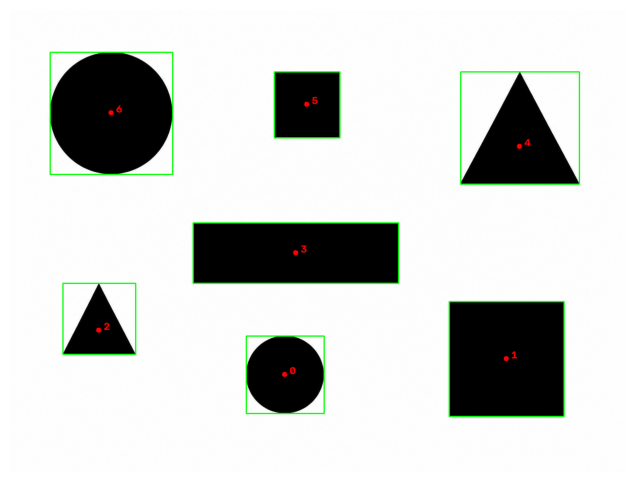

In [3]:
opisany = figury_rgb.copy()
for i, kontur in enumerate(kontury):
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    x, y, w, h = cv2.boundingRect(kontur)

    momenty = cv2.moments(kontur)
    cx = int(momenty["m10"] / momenty["m00"])
    cy = int(momenty["m01"] / momenty["m00"])
    cv2.rectangle(opisany, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.circle(opisany, (cx, cy), 6, (255, 0, 0), -1)
    cv2.putText(
        opisany, str(i), (cx + 12, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2
    )

    print(f"Kontur {i}: pole = {pole:.0f}, obwod = {obwod:.0f}, prostokat = {w} x {h}")

plt.figure(figsize=(10, 6))
plt.imshow(opisany)
plt.axis("off")
plt.show()

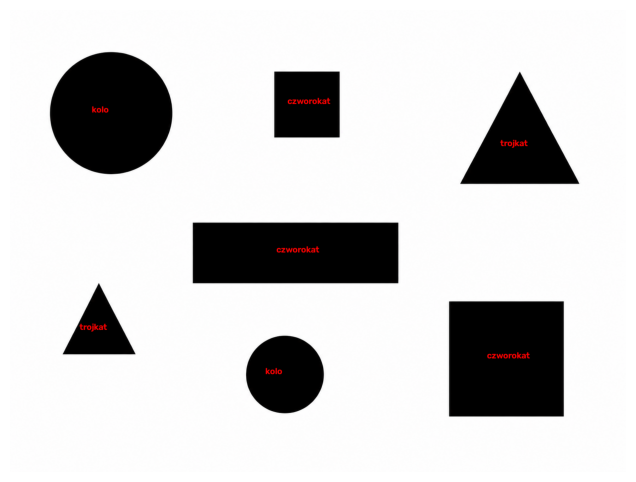

In [4]:
def rozpoznaj(kontur):
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    kolistosc = 4 * np.pi * pole / (obwod**2)
    przyblizenie = cv2.approxPolyDP(kontur, 0.03 * obwod, True)
    wierzcholki = len(przyblizenie)
    if wierzcholki == 3:
        return "trojkat"
    if wierzcholki == 4:
        return "czworokat"
    if kolistosc > 0.85:
        return "kolo"
    return "inna"


rozpoznane = figury_rgb.copy()
for kontur in kontury:
    momenty = cv2.moments(kontur)
    cx = int(momenty["m10"] / momenty["m00"])
    cy = int(momenty["m01"] / momenty["m00"])
    nazwa = rozpoznaj(kontur)
    cv2.putText(
        rozpoznane, nazwa, (cx - 45, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2
    )
plt.figure(figsize=(10, 6))
plt.imshow(rozpoznane)
plt.axis("off")
plt.show()

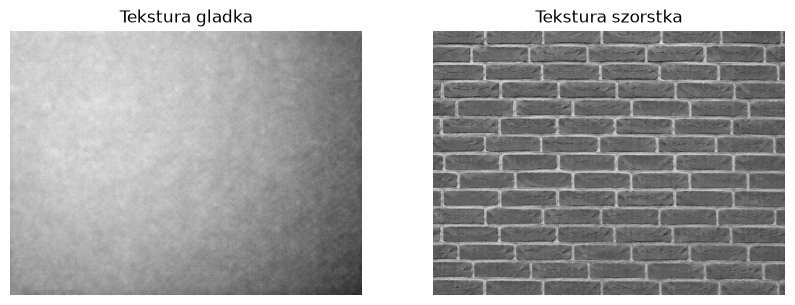

Gladka: srednia = 218.6 , odchylenie = 4.0
Szorstka: srednia = 113.2 , odchylenie = 32.4


In [5]:
gladka = cv2.imread("tekstura_gladka.jpg")
szorstka = cv2.imread("tekstura_szorstka.jpg")
gladka_szara = cv2.cvtColor(gladka, cv2.COLOR_BGR2GRAY)
szorstka_szara = cv2.cvtColor(szorstka, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gladka_szara, cmap="gray")
plt.title("Tekstura gladka")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(szorstka_szara, cmap="gray")
plt.title("Tekstura szorstka")
plt.axis("off")
plt.show()
print(
    "Gladka: srednia =",
    round(gladka_szara.mean(), 1),
    ", odchylenie =",
    round(gladka_szara.std(), 1),
)
print(
    "Szorstka: srednia =",
    round(szorstka_szara.mean(), 1),
    ", odchylenie =",
    round(szorstka_szara.std(), 1),
)

Ta sama tekstura: 1.0
Rozne tekstury: -0.14


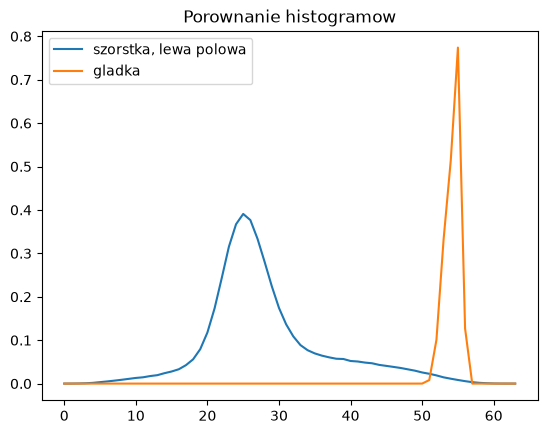

In [6]:
def histogram_znormalizowany(fragment):
    hist = cv2.calcHist([fragment], [0], None, [64], [0, 256])
    return cv2.normalize(hist, hist).flatten()


wys, szer = szorstka_szara.shape
lewa = szorstka_szara[:, : szer // 2]
prawa = szorstka_szara[:, szer // 2 :]
h_lewa = histogram_znormalizowany(lewa)
h_prawa = histogram_znormalizowany(prawa)
h_gladka = histogram_znormalizowany(gladka_szara)
print(
    "Ta sama tekstura:", round(cv2.compareHist(h_lewa, h_prawa, cv2.HISTCMP_CORREL), 2)
)
print(
    "Rozne tekstury:", round(cv2.compareHist(h_lewa, h_gladka, cv2.HISTCMP_CORREL), 2)
)
plt.plot(h_lewa, label="szorstka, lewa polowa")
plt.plot(h_gladka, label="gladka")
plt.title("Porownanie histogramow")
plt.legend()
plt.show()